<a href="https://colab.research.google.com/github/Narmadha-H/MLA0202-FML/blob/main/ML09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Degree    Train RMSE   Test RMSE  Train R2   Test R2
1              1.811       1.767     0.050     0.063
2              0.902       1.066     0.764     0.659
10             0.554       4.467     0.911    -4.990

Lowest test error is at degree 2


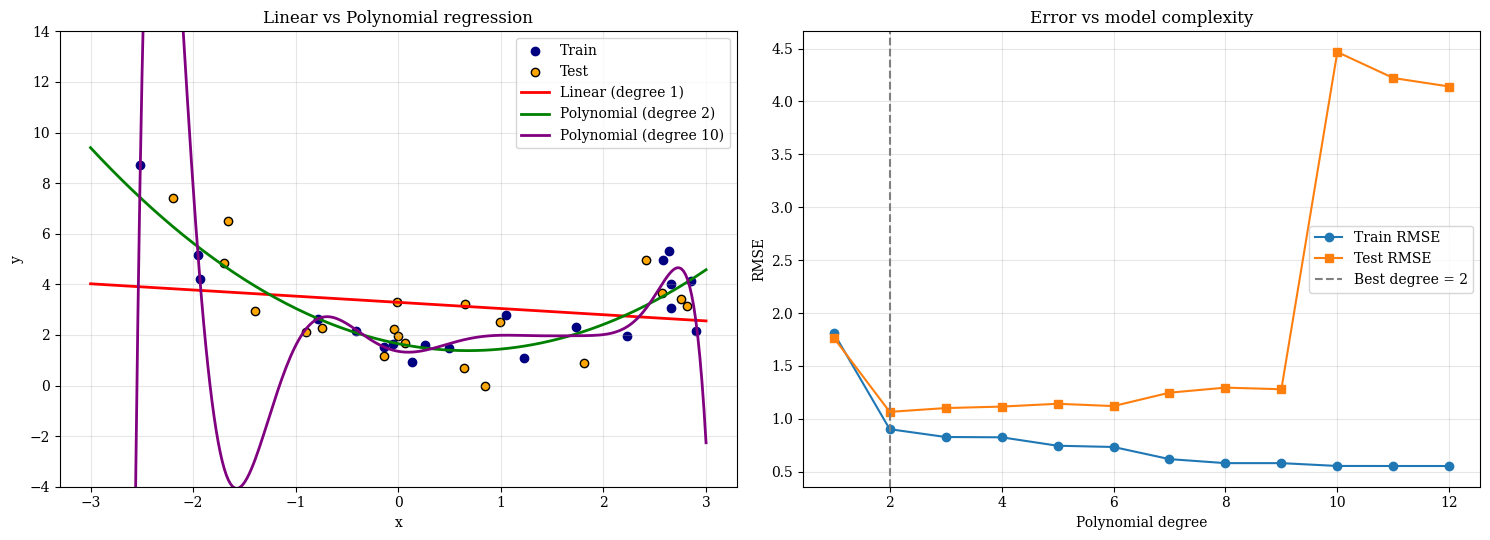

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "serif"

rng = np.random.default_rng(4)
x = rng.uniform(-3, 3, 40)
y = 0.5 * x**2 - x + 2 + rng.normal(0, 1.2, 40)      # true relation is quadratic + noise

idx = rng.permutation(40)
tr, te = idx[:20], idx[20:]
x_tr, y_tr, x_te, y_te = x[tr], y[tr], x[te], y[te]

def fit_poly(x, y, degree):
    return np.linalg.lstsq(np.vander(x, degree + 1), y, rcond=None)[0]   # least squares

def predict(coef, x):
    return np.vander(x, len(coef)) @ coef

def rmse(a, b): return np.sqrt(np.mean((a - b) ** 2))
def r2(a, b):   return 1 - np.sum((a - b) ** 2) / np.sum((a - a.mean()) ** 2)

print(f"{'Degree':<8}{'Train RMSE':>12}{'Test RMSE':>12}{'Train R2':>10}{'Test R2':>10}")
models = {}
for d in (1, 2, 10):
    c = fit_poly(x_tr, y_tr, d); models[d] = c
    print(f"{d:<8}{rmse(y_tr, predict(c, x_tr)):>12.3f}{rmse(y_te, predict(c, x_te)):>12.3f}"
          f"{r2(y_tr, predict(c, x_tr)):>10.3f}{r2(y_te, predict(c, x_te)):>10.3f}")

# error for every degree
degrees = range(1, 13)
tr_err, te_err = [], []
for d in degrees:
    c = fit_poly(x_tr, y_tr, d)
    tr_err.append(rmse(y_tr, predict(c, x_tr))); te_err.append(rmse(y_te, predict(c, x_te)))
best = list(degrees)[int(np.argmin(te_err))]
print(f"\nLowest test error is at degree {best}")

# ---- Graphs
xs = np.linspace(-3, 3, 300)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
ax[0].scatter(x_tr, y_tr, c="navy", label="Train"); ax[0].scatter(x_te, y_te, c="orange", edgecolors="k", label="Test")
for d, col, lab in [(1, "red", "Linear (degree 1)"), (2, "green", "Polynomial (degree 2)"), (10, "purple", "Polynomial (degree 10)")]:
    ax[0].plot(xs, predict(models[d], xs), color=col, lw=2, label=lab)
ax[0].set_ylim(-4, 14); ax[0].set_xlabel("x"); ax[0].set_ylabel("y")
ax[0].set_title("Linear vs Polynomial regression"); ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot(list(degrees), tr_err, "o-", label="Train RMSE")
ax[1].plot(list(degrees), te_err, "s-", label="Test RMSE")
ax[1].axvline(best, color="gray", ls="--", label=f"Best degree = {best}")
ax[1].set_xlabel("Polynomial degree"); ax[1].set_ylabel("RMSE")
ax[1].set_title("Error vs model complexity"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()